<a href="https://colab.research.google.com/github/Hema392/ITA0314-Mobile-Computing-/blob/main/Exp21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


EXPERIMENT 21: OFDMA SCHEDULER

Scheduler | User Throughputs | Total | Jain Index
RR [1.235 0.996 0.703 0.479 0.297 0.152] 3.861 0.741
MaxCI [6.061e+00 1.630e+00 1.990e-01 1.500e-02 2.000e-03 0.000e+00] 7.906 0.264
PF [1.689 1.375 1.038 0.741 0.476 0.257] 5.576 0.778


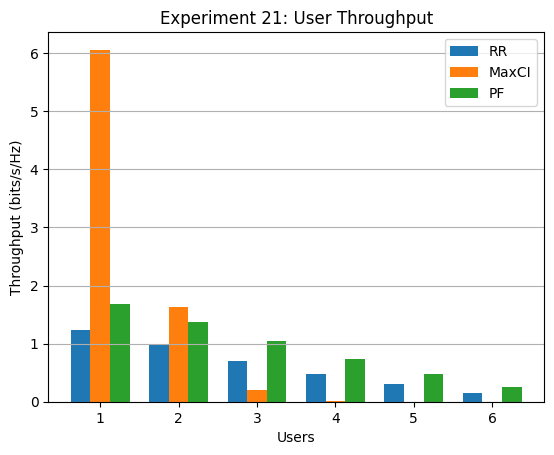

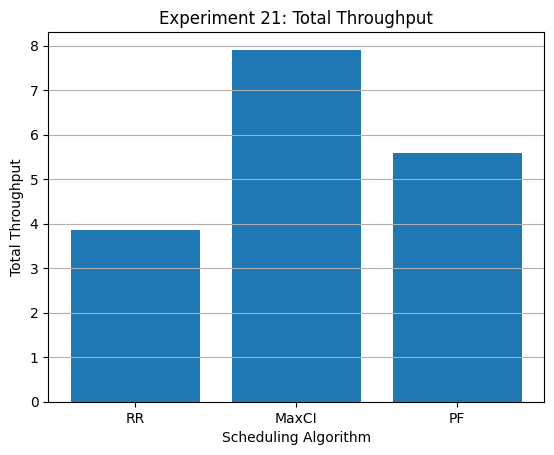

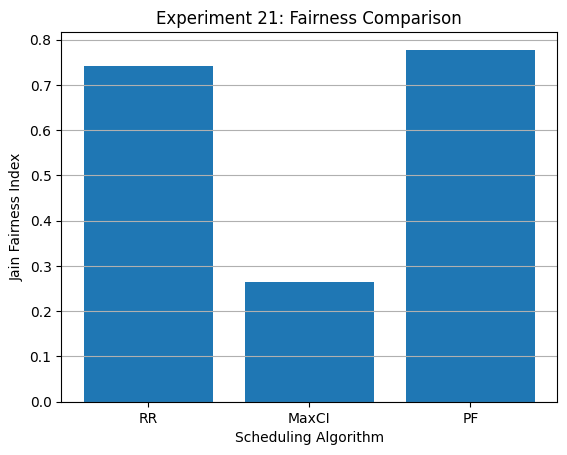

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
print("\nEXPERIMENT 21: OFDMA SCHEDULER")

rng = np.random.default_rng(1)

U = 6
TTI = 2000

mean_snr_db = np.array([25,20,15,10,5,0])
mean_snr = 10**(mean_snr_db/10)

rate = np.log2(
    1 + mean_snr*rng.exponential(1.0,(TTI,U))
)

def jain(x):
    return x.sum()**2/(len(x)*(x**2).sum())

def simulate(policy):
    served = np.zeros(U)
    avg = np.ones(U)

    for t in range(TTI):

        if policy == 'RR':
            u = t % U

        elif policy == 'MaxCI':
            u = np.argmax(rate[t])

        else:
            u = np.argmax(rate[t]/avg)

        served[u] += rate[t,u]

        inst = np.zeros(U)
        inst[u] = rate[t,u]

        avg = 0.99*avg + 0.01*inst

    return served/TTI

results = {}

print("\nScheduler | User Throughputs | Total | Jain Index")

for p in ['RR','MaxCI','PF']:
    th = simulate(p)
    results[p] = th

    print(p, np.round(th,3),
          round(th.sum(),3),
          round(jain(th),3))

plt.figure()
users = np.arange(1,U+1)
width = 0.25

for i,p in enumerate(['RR','MaxCI','PF']):
    plt.bar(users+(i-1)*width,
            results[p], width, label=p)

plt.xlabel("Users")
plt.ylabel("Throughput (bits/s/Hz)")
plt.title("Experiment 21: User Throughput")
plt.xticks(users)
plt.legend()
plt.grid(axis='y')
plt.show()

policies = ['RR','MaxCI','PF']
totals = [results[p].sum() for p in policies]
fairness = [jain(results[p]) for p in policies]

plt.figure()
plt.bar(policies, totals)
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Total Throughput")
plt.title("Experiment 21: Total Throughput")
plt.grid(axis='y')
plt.show()

plt.figure()
plt.bar(policies, fairness)
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Jain Fairness Index")
plt.title("Experiment 21: Fairness Comparison")
plt.grid(axis='y')
plt.show()

